In [4]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv("/Users/k.yukhlina/IronHack/Week_5/Day_1/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape

(2443651, 9)

In [6]:
df.dtypes

Task was destroyed but it is pending!
task: <Task pending name='Task-39' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-40' coro=<Kernel.shell_main() running at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/zmq/eventloop/zmqstream.py:563]>
<frozen abc>:123: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
Task was destroyed but it is pending!
task: <Task pending name='Task-40' coro=<Kernel.shell_main() running at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


uid                    int64
asin                     str
title                    str
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category                 str
dtype: object

In [7]:
# unique datatypes in dataframe
list(set(df.dtypes.tolist()))

[dtype('int64'),
 <StringDtype(storage='python', na_value=nan)>,
 dtype('bool'),
 dtype('float64')]

In [8]:
# numerical datatypes 
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='str')

In [9]:
# object datatypes
df.select_dtypes("object").columns

/var/folders/1q/2t5621cd5kz7blvfr_nw9dl80000gn/T/ipykernel_3157/2569990773.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes("object").columns


Index(['asin', 'title', 'category'], dtype='str')

In [20]:
df.select_dtypes("object").nunique().sort_values(ascending=False)

/var/folders/1q/2t5621cd5kz7blvfr_nw9dl80000gn/T/ipykernel_3157/3982989784.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes("object").nunique().sort_values(ascending=False)


asin        2222742
title       2077591
category        296
dtype: int64

**Conclusion.** We have too many categories, and we can't use all of it in one graph

# Data Cleaning

Checking for Missing Data

Missing data can influence our analysis. It's essential to identify and handle them appropriately.

In [10]:
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [11]:
df.drop("uid", inplace=True, axis=1)

# Part 1: Understanding Product Categories
**Business Question:** What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

**Frequency Tables:**

Generate a frequency table for the product category. Which are the top 5 most listed product categories? 

In [18]:
product_category = df.category
top_5_product_category = product_category.value_counts().head()
top_5_product_category

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

**Conclusion.** Top 5 most listed product categories: 
- 'Sports & Outdoors',
- 'Beauty',
- 'Handmade Clothing, Shoes & Accessories',
- 'Bath & Body',
- 'Birthday Gifts'.

Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories. For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

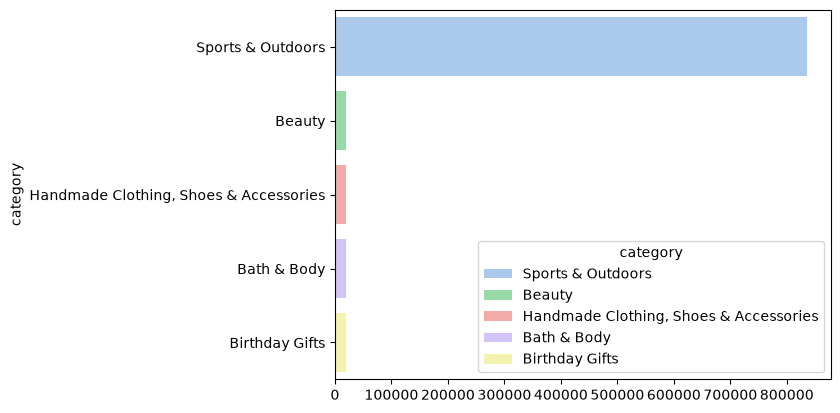

In [19]:
distrib_prod_cat = sns.barplot(y = top_5_product_category.index, x=top_5_product_category.values, hue=top_5_product_category.index, palette="pastel6", legend=True)
sns.move_legend(distrib_prod_cat, "lower right")

**Conclusion.** We have 296 different "categories"and it is useless to put all of them in one plot. In this situation the better to use top-5 product categories

# Part 2: Delving into Product Pricing
**Business Question:** How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

**1. Measures of Centrality:**

- Calculate the mean, median, and mode for the price of products.


In [233]:
avg_price = df["price"].mean().round(2)
median_price = df["price"].median()
mode_price = df["price"].mode()

print("Mean:", avg_price)
print("Median:", median_price)
print("Mode:", mode_price)

Mean: 89.24
Median: 19.09
Mode: 0    9.99
Name: price, dtype: float64


- What's the average price point of products listed? How does this compare with the most common price point (mode)?

**Conclusion.** The avarage price = 89.24. The mode of price = 9.99, and this is the most popular price in the dataset. This may indicate that we have a very high prices (perhaps, more than mean)

**2. Measures of Dispersion:**

- Determine the variance, standard deviation, range, and interquartile range for product price.

In [181]:
print("Variance:", df["price"].var().round(2))
print("Standard deviation:", df["price"].std().round(2))
print("Range:", (df["price"].max()-df["price"].min()))

Variance: 119445.49
Standard deviation: 345.61
Range: 100000.0


In [39]:
# Check deision of dataset size by 4 quartile -> 610912 * 4 < (or almost equal to) 2443651 -> we can devide by 4 quartiles
2443651 / 4

610912.75

In [36]:
df["price_quantile"] = pd.qcut(df["price"], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
df.price_quantile.value_counts()

price_quantile
Q1    629239
Q3    612341
Q4    609043
Q2    593028
Name: count, dtype: int64

- How varied are the product prices? Are there any indicators of a significant spread in prices?

**Conclusion.** Whith mean price of '89.24' and a standart deviation of '345.61' the price have a huge variation. The dispersion is significantly skewed to the right by outliers

3. Visualizations:
- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..


In [69]:
skewness_price = df["price"].skew()
kurtosis_price = df["price"].kurtosis()

skewness_price, kurtosis_price

(np.float64(27.49297756628037), np.float64(4241.616412866521))

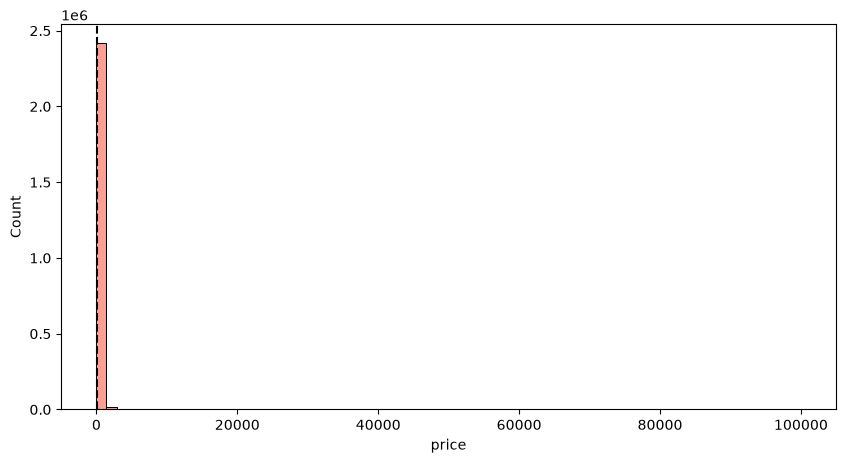

In [212]:
fig, axes = plt.subplots(figsize=(10, 5))
axes.axvline(df["price"].mean(), color="black", linestyle="--")
sns.histplot(df["price"], bins=70, color="salmon", ax=axes);
plt.show()

**Conclusion 1.** The histogram displays extreme number of prices less than '20000' but the prices on x axis ends after 100000 - it means we hav outliers in prices > 20000. To see tham we need to use logarithmic  

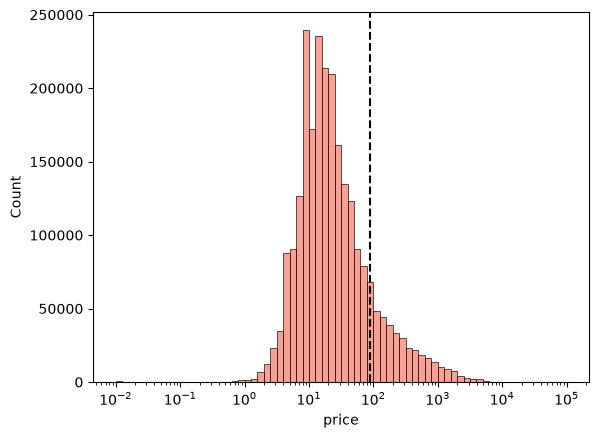

In [220]:
fig, axes = plt.subplots()
axes.axvline(df["price"].mean(), color="black", linestyle="--")
sns.histplot(df["price"], bins=70, color="salmon", ax=axes, log_scale=True);
plt.show()

**Conclusion 2.** On logarithmic scale histogram we can identify dispersion skewed to the right. The median also skewed to right

- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

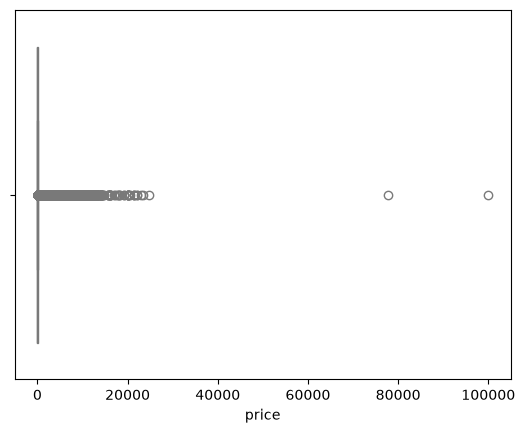

In [190]:
sns.boxplot(x = df["price"], color="lightblue");

**Conclusion.** On a box plot displayed outliers with significantly higher prices: '80000' and '100000'

# Part 3: Unpacking Product Ratings

**Business Question:** How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

**1. Measures of Centrality:**

- Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

In [231]:
avg_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()
print("Mean:", avg_rating.round(2))
print("Median:", median_rating)
print("Mode:", mode_rating)

Mean: 2.15
Median: 0.0
Mode: 0    0.0
Name: stars, dtype: float64


**Conclisions:**
- Dataset contains products with mostly low ratings (< 3.0)
- The most frequent rating in the dataset - 0.0
- The central value of column "stars" - 0.0

**2. Measures of Dispersion:**

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?


In [236]:
variance_rating = df["stars"].var().round(2)
std_rating = df["stars"].std().round(2)
print("Mean:", variance_rating)
print("Median:", std_rating)

Mean: 4.82
Median: 2.19


In [246]:
((df["stars"] == 0).sum() *100) / df.shape[0]

np.float64(50.15613931776674)

In [243]:
df["stars"].describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [253]:
((df["reviews"] == 0).sum() *100) / df.shape[0]

np.float64(50.15613931776674)

**Conclusions:**
- Approximately 50% data of column "stars" in dataset contains '0.0'. Thats because we cannot split our column into 4 bins using previous approach "pd.qcut(df["stars"], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])" (error retrieved "Value error: Bin edges must be unique: Index ([0.0, 0.0, 0.0, 4.4, 5.0], <...>).")
- Approximately 50% data of column "reviews" are also contains '0.0'
- Interquartile range prepared with .describe() method
- Customer reting is inconsistent

**3. Shape of the Distribution:**

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [257]:
skewness_rating = df['stars'].skew().round(2)
kurtosis_rating = df['stars'].kurtosis().round(2)
skewness_rating, kurtosis_rating

(np.float64(0.08), np.float64(-1.93))

In [259]:
"""
if skewness_rating < -0.50 & skewness_rating < 0.50:
    print("Symmetrical distribution")
elif skewness_rating > 0.50 & skewness_rating < 1.00:
    print("Skewed right")
elif skewness_rating > -0.50 or skewness_rating < -1.00:
    print("Skewed left") 


if kurtosis_rating > 3.00:
    print("Leptokurtic. Distribution has heavier tails and a sharper peak compared to a normal distribution. Shows a higher chance of extreme outliers or rare extreme events")
elif kurtosis_rating < 3.00:
    print("Platykurtic. Has thin or light tails. Shows a lower chance of extreme outliers than a normal distribution.")
elif kurtosis_rating == 3.00:
    print("Mesokurtic. Matches the normal distribution. Has standard outlier behavior.")
 """

'\nif skewness_rating < -0.50 & skewness_rating < 0.50:\n    print("Symmetrical distribution")\nelif skewness_rating > 0.50 & skewness_rating < 1.00:\n    print("Skewed right")\nelif skewness_rating > -0.50 or skewness_rating < -1.00:\n    print("Skewed left") \n\n\nif kurtosis_rating > 3.00:\n    print("Leptokurtic. Distribution has heavier tails and a sharper peak compared to a normal distribution. Shows a higher chance of extreme outliers or rare extreme events")\nelif kurtosis_rating < 3.00:\n    print("Platykurtic. Has thin or light tails. Shows a lower chance of extreme outliers than a normal distribution.")\nelif kurtosis_rating == 3.00:\n    print("Mesokurtic. Matches the normal distribution. Has standard outlier behavior.")\n '

**Conclusion:**

**4. Visualizations:**

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

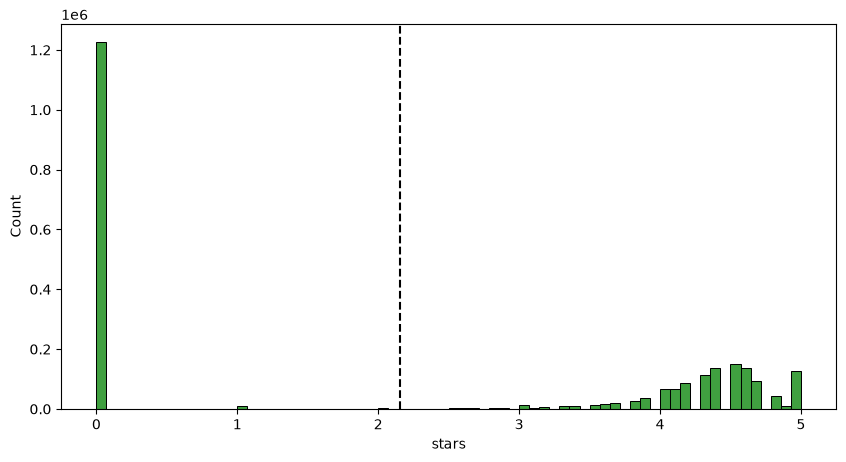

In [262]:
fig, axes = plt.subplots(figsize=(10, 5))
axes.axvline(df["stars"].mean(), color="black", linestyle="--")
sns.histplot(df["stars"], bins=70, color="green", ax=axes);
plt.show()